In [1]:
import numpy as np
from scipy.integrate import odeint
import matplotlib.pyplot as plt
plt.rcParams['text.usetex'] = True
plt.rcParams['font.family'] = 'serif'          # or 'sans-serif', 'monospace', etc.
plt.rcParams['font.serif'] = ['Computer Modern Serif']  # You can specify specific fonts
%run algorithms.py
%run utils.py
#plt.rcParams.update(get_rcparams())

## Hindmarsh-Rose model

In [2]:
## define system

def hindmarsh_rose(y, t):
    x1, x2, x3 = y

    # Fixed parameters
    a, b, c, d = 1, 3, 1, 5
    s, x_r = 4, -8 / 5
    # Control parameters
    r, I = 0.005, 3.25

    xdot = x2 - a * x1**3 + b * x1**2 - x3 + I
    ydot = c - d * x1**2 - x2
    zdot = r * (s * (x1 - x_r) - x3)
    sys = np.array([xdot, ydot, zdot])
    return sys


In [3]:
# Generate data with following parameters for the above defined system

# Create time domain
m = 1000                           # of data points
#dt = 1e-3
t_span = np.linspace(0, 50, m)     # time-span of solution 


# Initial condition
x0 = 0.1                             # Initial concentration x
y0 = 0.1                               # Initial concentration y
z0 = 0.1                               # Initial concentration z
yzero = [x0, y0, z0]

data = generate_ode_data(system=hindmarsh_rose)          # Data from the system

X_sol = data.solve_system(yzero, t_span)

X, X_dot = data.data_matrices(X_sol, t_span)

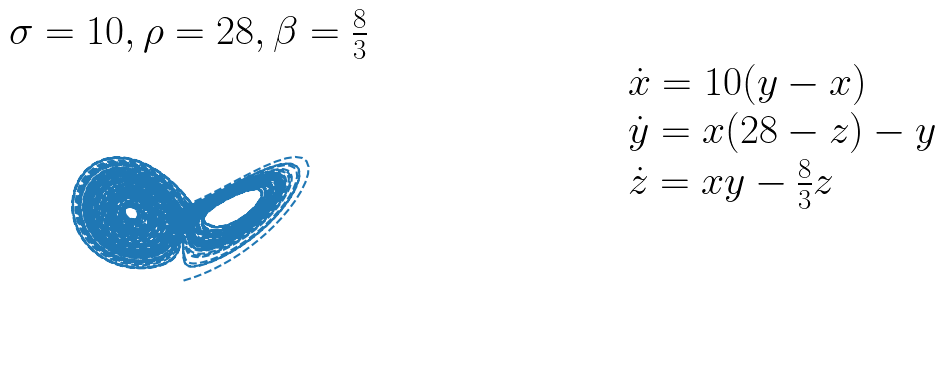

In [ ]:
## lorenz63

def lorenz63(y, t):
    x, y, z = y

    sigma, rho, beta = 10, 28, 8/3
   # alpha = 5

    # Equations for the Lorenz system
    xdot = sigma * (y - x) #+ np.tanh(alpha * x)
    ydot = x * (rho - z) - y
    zdot = x * y - beta * z
    
    sys = np.array([xdot, ydot, zdot])
    return sys


# Generate data with following parameters for the above defined system

# Create time domain
m = 10000                           # of data points
#dt = 1e-3
t_span = np.linspace(0, 100, m)     # time-span of solution 


# Initial condition
x0 = 0.1                             # Initial concentration x
y0 = 0.1                               # Initial concentration y
z0 = 0.1                               # Initial concentration z
yzero = [x0, y0, z0]

data = generate_ode_data(system=lorenz63)          # Data from the system

X_sol = data.solve_system(yzero, t_span)

X, X_dot = data.data_matrices(X_sol, t_span)

fig = plt.figure(figsize=(10, 4))

ax = fig.add_subplot(121, projection='3d')
ax.plot(X[0], X[1], X[2], '--')
#ax.quiver(100,20,20, 1,1,1, color='r', arrow_length_ratio=10.1)
ax.set_title(r'$\sigma = 10, \rho = 28, \beta = \frac{8}{3}$', fontsize=30)
ax.set_axis_off()

# Right panel for LaTeX
ax_text = fig.add_subplot(122)
fig.text(
    0.7, 0.5,
    r'$\dot{x} = 10 (y - x)$' '\n'
    r'$\dot{y} = x(28 - z) - y$' '\n'
    r'$\dot{z} = xy - \frac{8}{3} z$',
    fontsize=30
)
ax_text.axis('off')
plt.tight_layout()
#plt.savefig('./figures/chap1_lorenz_system.png', bbox_inches="tight", dpi=300)
plt.show()


## Apply SINDy

In [4]:
def psi_hindmarsh_rose(X):
    """Returns transformed data matrices using parametric set of basis functions"""
    return np.vstack(
        (np.ones(X.shape[1]), X[0, :], X[1, :], X[2, :], X[0, :]*X[1, :], X[1, :]**3, X[0, :]*X[2, :]**2, X[0, :] ** 2, X[0, :] ** 3)
    )

#I = 15.25
psi_x = psi_hindmarsh_rose(X)
xi_hr = sindy_ode(X, X_dot, psi_x)

In [5]:
xi_hr

array([[ 3.25e+00,  0.00e+00,  1.00e+00, -1.00e+00,  0.00e+00,  0.00e+00,
         0.00e+00,  3.00e+00, -1.00e+00],
       [ 1.00e+00,  0.00e+00, -1.00e+00,  0.00e+00,  0.00e+00,  0.00e+00,
         0.00e+00, -5.00e+00,  0.00e+00],
       [ 3.20e-02,  2.00e-02,  0.00e+00, -5.00e-03,  0.00e+00,  0.00e+00,
         0.00e+00,  0.00e+00,  0.00e+00]])

In [6]:
def Derivatives(y,t):
    x1, x2, x3 = y
    basis = np.array([np.ones_like(x1), x1, x2, x3, x1*x2, x2**3, x1*x3**2, x1**2, x1**3])                         # Basis functions
    D = np.dot(xi_hr, basis)                                                                           # Recovered system
    return D

X_sindy = odeint(Derivatives, yzero, t_span).T # make shape (d, m) 
# psiX = psi_hindmarsh_rose(X)
print(cost_sindy(xi_hr, X_dot, psi_x))

1.8620627280637714e-26


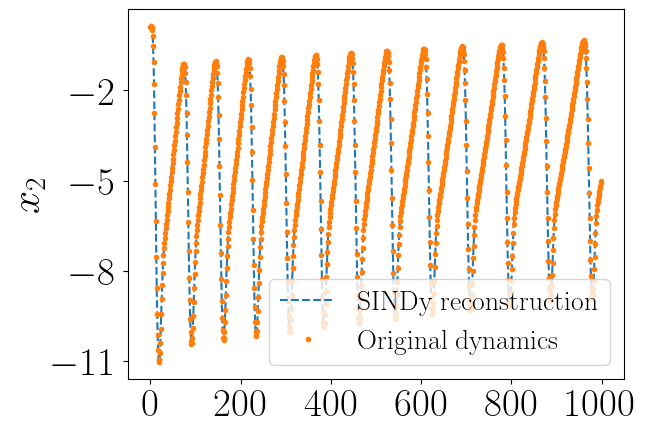

In [7]:
# 3d-plot
plot = '2d' # '2d' or'3d'

if plot == '2d':
    xticks = np.arange(0, 1100, 200)
    yticks = np.arange(-11, 2, 3)
    with nice_2d_plot(xticks=xticks, yticks=yticks) as (fig, ax):

        ax.plot(X_sindy[1, :], '--', label='SINDy reconstruction')
        ax.plot(X[1,:], '.', label='Original dynamics')
        ax.set_ylabel("$x_2$", fontsize=30)
        ax.legend(loc='lower right', fontsize=20)
        #plt.savefig('./figures/chap2_hr_reconstruction_1d.pdf', bbox_inches="tight", dpi=300)

if plot == '3d':
    # # 3d-plot

    xticks = np.arange(-1, 3.5, 1)
    yticks = np.arange(-11, 0, 3)
    zticks = np.arange(0.1, 2, 0.5)
    with nice_3d_plot(xticks=xticks, yticks=yticks, zticks=zticks) as (fig, ax):

        ax.plot(X_sindy[0, :], X_sindy[1, :], X_sindy[2, :], '--', label='SINDy reconstruction')
        ax.plot(X[0,:], X[1,:], X[2,:], '.', label='Original dynamics')
        ax.legend(loc='upper right', fontsize=18)
        #plt.savefig('./figures/chap2_hr_reconstruction_3d.pdf', bbox_inches="tight", dpi=300)
   

## Limitation example (Thomas attractor)

In [ ]:

def thomas_system(y, t, b=0.2, beta=0.15):
    x1, x2, x3 = y
    dx1 = -b * x1 + np.sin(5*x2)- beta*x2*np.cos(x1)
    dx2 = -b * x2 + np.sin(x3)- beta*x3*np.cos(x2)
    dx3 = -b * x3 + np.sin(x1)- beta*x1*np.cos(x3)
    return np.array([dx1, dx2, dx3])


b=0.2
beta = 0.15
omega = 0.5    #TODO: change here for different omega values

def psi_thomas(X, omega):
    """Basis functions for the Thomas attractor"""
    x1 = X[0, :]
    x2 = X[1, :]
    x3 = X[2, :]
    
    return np.vstack([
        np.ones(X.shape[1]),  # constant term
        x1,
        x2,
        x3,
        np.sin(x1),
        np.sin(omega*x2),
        np.sin(x3),
        beta*x2*np.cos(x1),
        beta*x3*np.cos(x2),
        beta*x1*np.cos(x3),
        x1**2,
        x2**2,
        x3**2,
        x1 * x2
    ])


def Derivatives_thomas(y, t):
    x1, x2, x3 = y
    basis = np.array([
        1,
        x1,
        x2,
        x3,
        np.sin(x1),
        np.sin(omega*x2),
        np.sin(x3),
        beta*x2*np.cos(x1),
        beta*x3*np.cos(x2),
        beta*x1*np.cos(x3),
        x1**2,
        x2**2,
        x3**2,
        x1 * x2
    ])
    D = xi_thms @ basis
    return D


# Initial condition and time span
yzero = [0, 1, 1]
t_span = np.linspace(0, 100, 1000)

data = generate_ode_data(system=thomas_system)
X_sol = data.solve_system(yzero, t_span)
X, X_dot = data.data_matrices(X_sol, t_span)
psi_x = psi_thomas(X, omega)
xi_thms = sindy_ode(X, X_dot, psi_x)

X_sindy = odeint(Derivatives_thomas, yzero, t_span).T

print('Cost SINDy:', cost_sindy(xi_thms, X_dot, psi_x))


Cost SINDy: 202.3117695582093


/tmp/ipykernel_11932/1813205432.py:69: ODEintWarning: Excess work done on this call (perhaps wrong Dfun type). Run with full_output = 1 to get quantitative information.
  X_sindy = odeint(Derivatives_thomas, yzero, t_span).T


In [11]:
X.shape

(3, 1000)

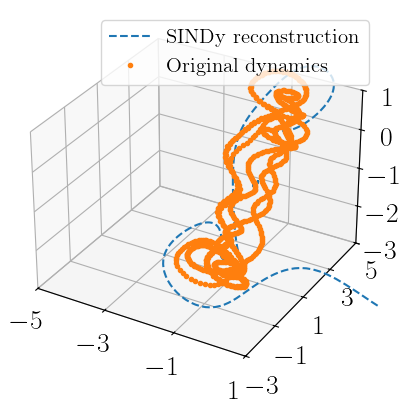

In [12]:
# 3d-plot
plot = '3d' # '2d' or'3d'

if plot == '2d':
    xticks = np.arange(0, 1100, 200)
    yticks = np.arange(-1, 3.5, 1)
    with nice_2d_plot(xticks=xticks, yticks=yticks) as (fig, ax):

        ax.plot(X_sindy[0, :], '--', label='SINDy reconstruction')
        ax.plot(X[0,:], '.', label='Original dynamics')
        ax.legend(loc='upper right', fontsize=15)
        #plt.savefig('./figures/hr_reconstruction_1d.pdf', bbox_inches="tight", dpi=300)

if plot == '3d':
    # # 3d-plot

    xticks = np.arange(-5, 2, 2)
    yticks = np.arange(-3, 6, 2)
    zticks = np.arange(-3, 2, 1)
    with nice_3d_plot(xticks=xticks, yticks=yticks, zticks=zticks) as (fig, ax):

        ax.plot(X_sindy[0, :], X_sindy[1, :], X_sindy[2, :], '--', label='SINDy reconstruction')
        ax.plot(X[0,:], X[1,:], X[2,:], '.', label='Original dynamics')
        ax.legend(loc='upper right', fontsize=15)
        #plt.savefig('./figures/chap2_thomas_reconstruction_omega1_3d.pdf', bbox_inches="tight", dpi=300)
   

In [5]:

omega_vals = np.linspace(0, 7, 50)

costs = []
for i in omega_vals:
    psi_x_exp = psi_thomas(X, omega=i)
    xi_thms_exp = sindy_ode(X, X_dot, psi_x_exp)
    X_sindy_exp = xi_thms_exp @ psi_x_exp
    costs.append(cost_sindy(xi_thms_exp, X_dot, psi_x_exp))



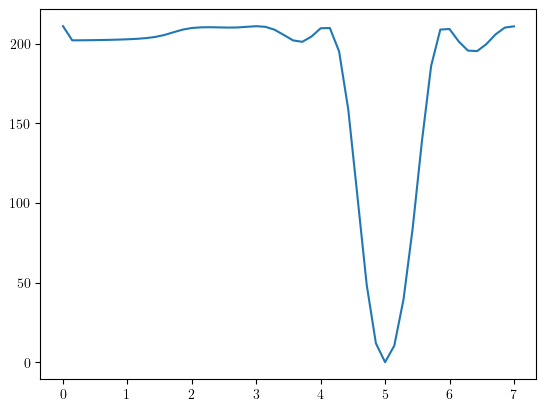

In [7]:
plt.plot(omega_vals, costs)